In [1]:
import pandas as pd
import numpy as np
import scipy.sparse as sp
import matplotlib.pyplot as plt
import seaborn as sns
from collections import OrderedDict

## Main Result

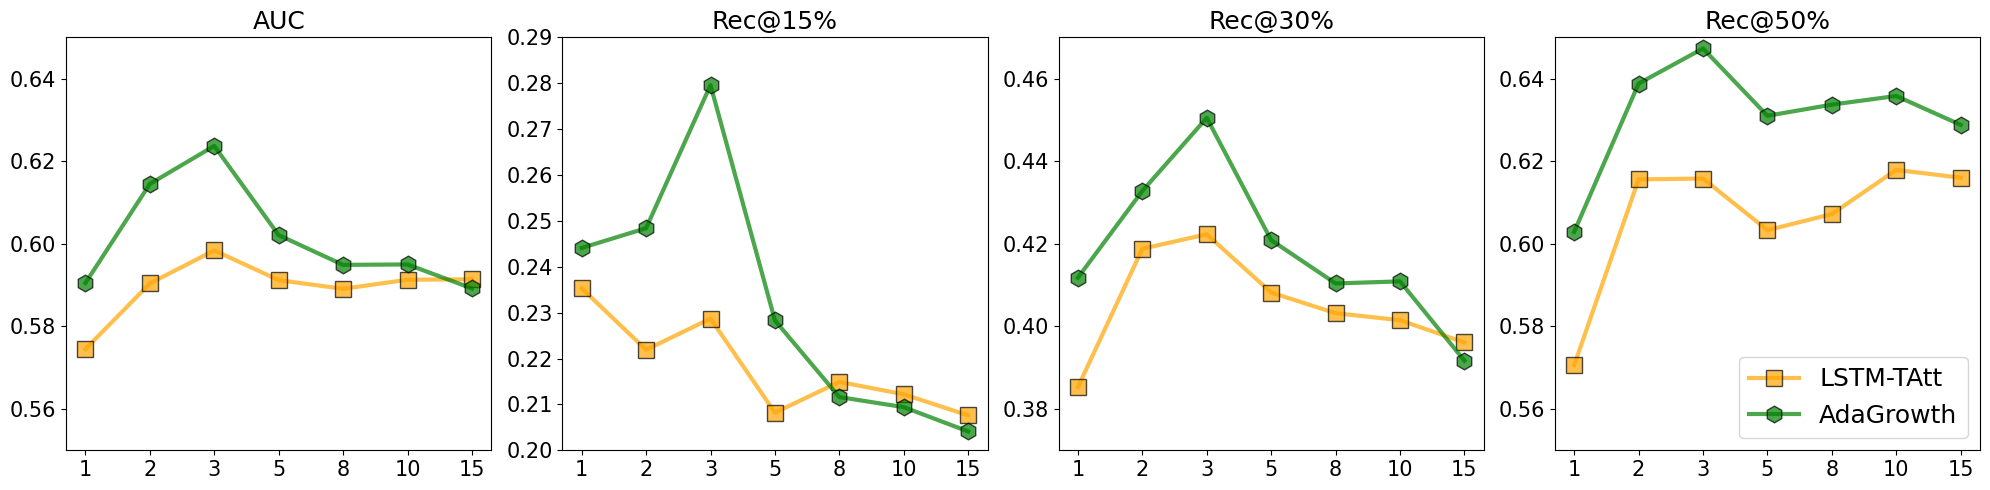

In [15]:
# oth reg

auc_d1 = (0.5745, 0.5904, 0.5984, 0.5912, 0.5891, 0.5913, 0.5914)
auc_d2 = (0.5905, 0.6145, 0.6237, 0.6021, 0.5949, 0.5950, 0.5892)

r1_d1 = (0.2353, 0.2219, 0.2287, 0.2082, 0.2149, 0.2122, 0.2076)
r1_d2 = (0.2441, 0.2484, 0.2796, 0.2283, 0.2116, 0.2094, 0.2041)

r2_d1 = (0.3853, 0.4188, 0.4223, 0.4082, 0.4032, 0.4015, 0.3961)
r2_d2 = (0.4118, 0.4328, 0.4505, 0.4209, 0.4104, 0.4109, 0.3917)

r3_d1 = (0.5706, 0.6156, 0.6158, 0.6033, 0.6072, 0.6179, 0.6160)
r3_d2 = (0.6029, 0.6388, 0.6473, 0.6310, 0.6337, 0.6358, 0.6288)

def plot_sen(ax, res, ymax, ymin, title):
    X = ('1', '2', '3', '5', '8', '10', '15')
    ax.errorbar(X, res[0], label='LSTM-TAtt', alpha=0.7, linewidth=3, marker='s', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='orange')
    ax.errorbar(X, res[1], label='AdaGrowth', alpha=0.7, linewidth=3, marker='h', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='green')
    ax.set_ylim(ymin, ymax)
    ax.tick_params(labelsize=15)
    ax.set_title(title, fontsize=18)
    


fig, axes = plt.subplots(1, 4, figsize=(20, 5))

plot_sen(axes[0], [auc_d1, auc_d2], ymax=0.65, ymin=0.55, title='AUC')
plot_sen(axes[1], [r1_d1, r1_d2], ymax=0.29, ymin=0.20, title='Rec@15%')
plot_sen(axes[2], [r2_d1, r2_d2], ymax=0.47, ymin=0.37, title='Rec@30%')
plot_sen(axes[3], [r3_d1, r3_d2], ymax=0.65, ymin=0.55, title='Rec@50%')
axes[3].legend(fontsize=18)

plt.tight_layout()   # 自动调整间距，防止重叠
plt.savefig('con_hori.jpg', dpi=500)
plt.show()

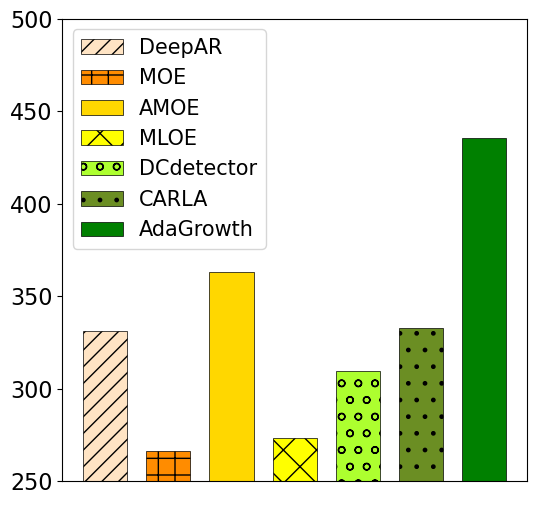

In [28]:
yM1 = (330.9650, 266.0000, 362.9150, 273.4550, 309.6650, 332.6690, 435.5480)
plt.figure(figsize=(6,6))
plt.bar(0.1, height=yM1[0], width=0.07, color='bisque', hatch='//', edgecolor='black', linewidth= 0.5, label='DeepAR')
plt.bar(0.2, height=yM1[1], width=0.07, color='darkorange', hatch='+', edgecolor='black', linewidth= 0.5, label='MOE')
plt.bar(0.3, height=yM1[2], width=0.07, color='gold', hatch='', edgecolor='black', linewidth= 0.5, label='AMOE')
plt.bar(0.4, height=yM1[3], width=0.07, color='yellow', hatch='x', edgecolor='black', linewidth= 0.5, label='MLOE')
plt.bar(0.5, height=yM1[4], width=0.07, color='greenyellow', hatch='o', edgecolor='black', linewidth= 0.5, label='DCdetector')
plt.bar(0.6, height=yM1[5], width=0.07, color='olivedrab', hatch='.', edgecolor='black', linewidth= 0.5, label='CARLA')
plt.bar(0.7, height=yM1[6], width=0.07, color='green', hatch='', edgecolor='black', linewidth= 0.5, label='AdaGrowth')
plt.tick_params(labelsize=16)
plt.xticks([])
plt.ylim(250,500)
plt.legend(loc='upper left', fontsize=15)
plt.savefig('econ15.jpg', dpi=500)
plt.show()

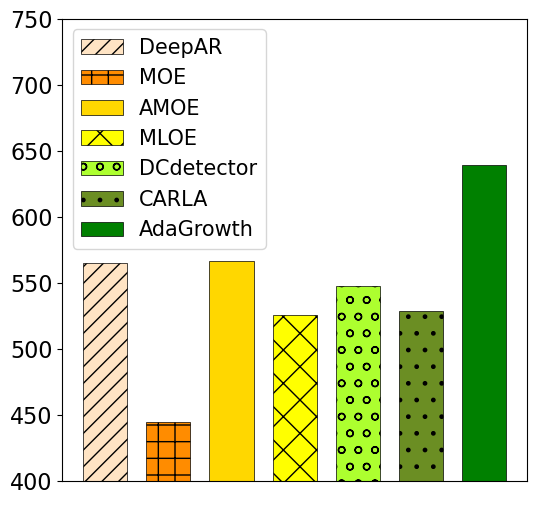

In [29]:
yM2 = (565.2280, 444.8830, 566.2930, 525.8230, 547.9750, 529.0180, 639.5650 )
plt.figure(figsize=(6,6))
plt.bar(0.1, height=yM2[0], width=0.07, color='bisque', hatch='//', edgecolor='black', linewidth= 0.5, label='DeepAR')
plt.bar(0.2, height=yM2[1], width=0.07, color='darkorange', hatch='+', edgecolor='black', linewidth= 0.5, label='MOE')
plt.bar(0.3, height=yM2[2], width=0.07, color='gold', hatch='', edgecolor='black', linewidth= 0.5, label='AMOE')
plt.bar(0.4, height=yM2[3], width=0.07, color='yellow', hatch='x', edgecolor='black', linewidth= 0.5, label='MLOE')
plt.bar(0.5, height=yM2[4], width=0.07, color='greenyellow', hatch='o', edgecolor='black', linewidth= 0.5, label='DCdetector')
plt.bar(0.6, height=yM2[5], width=0.07, color='olivedrab', hatch='.', edgecolor='black', linewidth= 0.5, label='CARLA')
plt.bar(0.7, height=yM2[6], width=0.07, color='green', hatch='', edgecolor='black', linewidth= 0.5, label='AdaGrowth')
plt.tick_params(labelsize=16)
plt.xticks([])
plt.ylim(400,750)
plt.legend(loc='upper left', fontsize=15)
plt.savefig('econ30.jpg', dpi=500)
plt.show()

<Figure size 500x500 with 0 Axes>

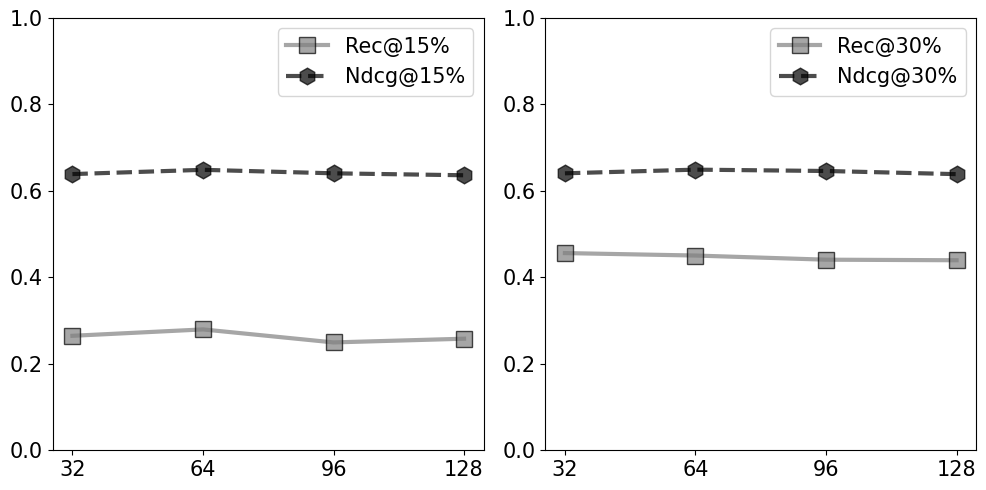

In [58]:
r1 = (0.2648, 0.2796, 0.2495, 0.2581 )
n1 = (0.6389, 0.6488, 0.6407, 0.6362 )
r2 = (0.4562, 0.4505, 0.4409, 0.4396  )
n2 = (0.6407, 0.6492, 0.6461, 0.6388  )

plt.figure(figsize=(5,5))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
def plot_dim(axes, rec, ndcg, S):
    X = ('32', '64', '96', '128')
    axes.errorbar(X, rec, label='Rec@'+S, alpha=0.7, linewidth=3, marker='s', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='grey')
    axes.errorbar(X, ndcg, label='Ndcg@'+S, alpha=0.7, linewidth=3, marker='h', linestyle='--', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='black')
    axes.set_ylim(0, 1)
    axes.tick_params(labelsize=15)
    axes.legend(fontsize=15)

plot_dim(axes[0], r1, n1, '15%')
plot_dim(axes[1], r2, n2, '30%')

plt.tight_layout()   # 自动调整间距，防止重叠
plt.savefig('sen_dim.jpg', dpi=500)
plt.show()

<Figure size 500x500 with 0 Axes>

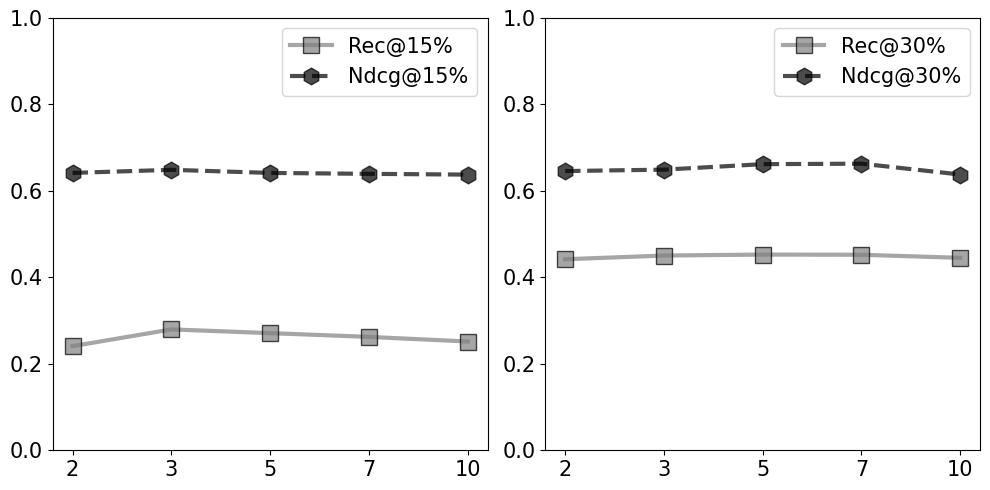

In [61]:
r1 = (0.2409, 0.2796, 0.2710, 0.2623, 0.2516)
n1 = (0.6416, 0.6488, 0.6416, 0.6395, 0.6377)
r2 = (0.4419, 0.4505, 0.4527, 0.4523, 0.4452)
n2 = (0.6459, 0.6492, 0.6619, 0.6630, 0.6379)

plt.figure(figsize=(5,5))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
def plot_dim(axes, rec, ndcg, S):
    X = ('2', '3', '5', '7', '10')
    axes.errorbar(X, rec, label='Rec@'+S, alpha=0.7, linewidth=3, marker='s', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='grey')
    axes.errorbar(X, ndcg, label='Ndcg@'+S, alpha=0.7, linewidth=3, marker='h', linestyle='--', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='black')
    axes.set_ylim(0, 1)
    axes.tick_params(labelsize=15)
    axes.legend(fontsize=15)

plot_dim(axes[0], r1, n1, '15%')
plot_dim(axes[1], r2, n2, '30%')

plt.tight_layout()   # 自动调整间距，防止重叠
plt.savefig('sen_K.jpg', dpi=500)
plt.show()

<Figure size 500x500 with 0 Axes>

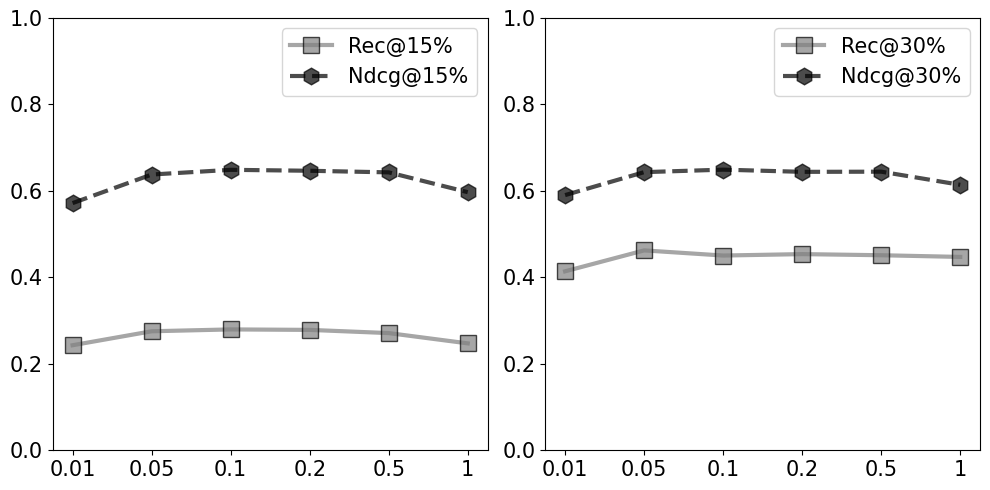

In [59]:
r1 = (0.2430, 0.2753, 0.2796, 0.2785, 0.2711, 0.2473)
n1 = (0.5718, 0.6379, 0.6488, 0.6466, 0.6429, 0.5971)
r2 = (0.4140, 0.4624, 0.4505, 0.4538, 0.4512, 0.4473)
n2 = (0.5903, 0.6434, 0.6492, 0.6441, 0.6445, 0.6141)

plt.figure(figsize=(5,5))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
def plot_dim(axes, rec, ndcg, S):
    X = ('0.01', '0.05', '0.1', '0.2', '0.5', '1')
    axes.errorbar(X, rec, label='Rec@'+S, alpha=0.7, linewidth=3, marker='s', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='grey')
    axes.errorbar(X, ndcg, label='Ndcg@'+S, alpha=0.7, linewidth=3, marker='h', linestyle='--', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='black')
    axes.set_ylim(0, 1)
    axes.tick_params(labelsize=15)
    axes.legend(fontsize=15)

plot_dim(axes[0], r1, n1, '15%')
plot_dim(axes[1], r2, n2, '30%')

plt.tight_layout()   # 自动调整间距，防止重叠
plt.savefig('sen_tai.jpg', dpi=500)
plt.show()

<Figure size 500x500 with 0 Axes>

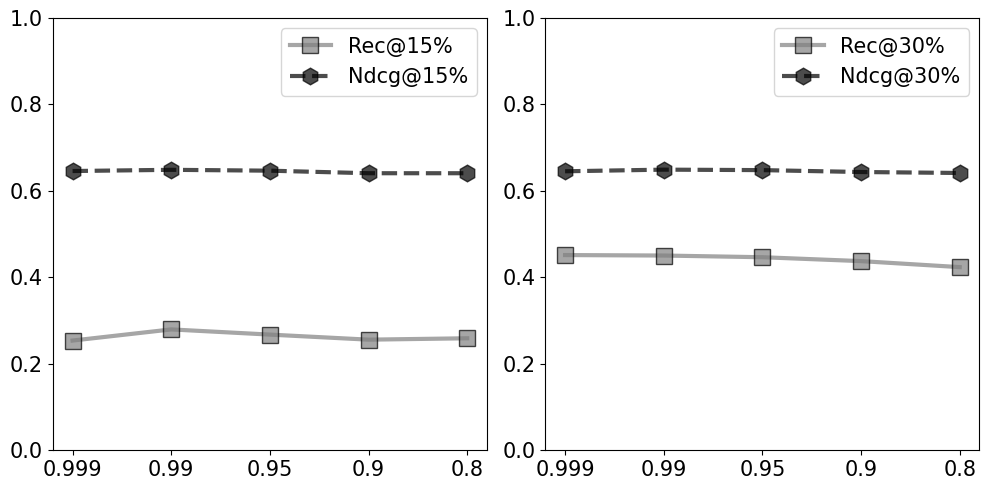

In [60]:
r1 = (0.2538, 0.2796, 0.2676, 0.2559, 0.2591)
n1 = (0.6460, 0.6488, 0.6468, 0.6409, 0.6409)
r2 = (0.4516, 0.4505, 0.4466, 0.4376, 0.4237)
n2 = (0.6454, 0.6492, 0.6481, 0.6437, 0.6415)

plt.figure(figsize=(5,5))

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
def plot_dim(axes, rec, ndcg, S):
    X = ('0.999', '0.99', '0.95', '0.9', '0.8')
    axes.errorbar(X, rec, label='Rec@'+S, alpha=0.7, linewidth=3, marker='s', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='grey')
    axes.errorbar(X, ndcg, label='Ndcg@'+S, alpha=0.7, linewidth=3, marker='h', linestyle='--', elinewidth=1.5, capsize=2, capthick=3, ms=12, mec='black', color='black')
    axes.set_ylim(0, 1)
    axes.tick_params(labelsize=15)
    axes.legend(fontsize=15)

plot_dim(axes[0], r1, n1, '15%')
plot_dim(axes[1], r2, n2, '30%')

plt.tight_layout()   # 自动调整间距，防止重叠
plt.savefig('sen_rho.jpg', dpi=500)
plt.show()